Introduction: 
Our group is comparing Pittsburgh neighborhoods using several measures of neighborhood quality. For my individual metric, I chose recorded code violations because they provide one way to look at property conditions and neighborhood maintenance. My approach is to count the recorded violations in each neighborhood, rank neighborhoods from fewest to most, and convert the ranks into proportions so they can be compared with my teammates’ results. This metric measures recorded violations, not overall safety or quality of life. Other approaches could account for population, neighborhood area, or inspection frequency, but this analysis uses total recorded violations to keep the metric straightforward and consistent.

Inspect the dataset structure and missing values before cleaning.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv('dataV.csv')
print("=== Dataset Information ===")
df.info()
print("\n=== Dataset Shape (Rows, Columns) ===")
print(df.shape)
print("\n=== Column Names ===")
print(df.columns.tolist())
print("\n=== First 5 Rows ===")
display(df.head())
print("\n=== Missing Values ===")
print(df.isnull().sum())import pandas as pd
import matplotlib.pyplot as plt

# Load the original WPRDC data
df = pd.read_csv('dataV.csv')
print('=== Dataset Information ===')
df.info()
print('\n=== Dataset Shape ===', df.shape)
print('\n=== Columns ===', df.columns.tolist())
print('\n=== Missing Values ===')
print(df.isnull().sum())
display(df.head())

=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653152 entries, 0 to 653151
Data columns (total 23 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   _id                           653152 non-null  int64  
 1   casefile_number               653152 non-null  object 
 2   address                       611967 non-null  object 
 3   parcel_id                     653152 non-null  object 
 4   status                        653152 non-null  object 
 5   case_file_type                653152 non-null  object 
 6   investigation_date            440028 non-null  object 
 7   investigation_outcome         440028 non-null  object 
 8   investigation_findings        439995 non-null  object 
 9   violation_description         158377 non-null  object 
 10  violation_code_section        158347 non-null  object 
 11  violation_code_section_title  158346 non-null  object 
 12  violation_code_s

,_id,casefile_number,address,parcel_id,status,case_file_type,investigation_date,investigation_outcome,investigation_findings,violation_description,...,violation_spec_instructions,court_date,court_time,docket_number,court_decision,latitude,longitude,neighborhood,ward,council_district
0,123317800,CF-ES-2023-022875,"1006 STANFORD RD, Pittsburgh, PA 15212-",0076A00120000000,Closed,Early Set Out,2023-06-02,No Violation Found,"DPW inspector visited location, No violation c...",NaN,...,NaN,NaN,NaN,NaN,NaN,40.480898,-80.029766,Brighton Heights,27.0,1.0
1,123317801,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-15,Violation Found,violations found,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
2,123317802,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-25,Violation Resolved,violation corrected grass cut,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
3,123317803,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,NaN,NaN,NaN,"Rear of parcel by garage and along fence, Larg...",...,Weeds/overgrowth. All exterior property shall ...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
4,123317804,CF-PLI-2020-011293,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-08-06,Violation Found,Cited for overgrowth,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0



=== Missing Values ===
_id                                  0
casefile_number                      0
address                          41185
parcel_id                            0
status                               0
case_file_type                       0
investigation_date              213124
investigation_outcome           213124
investigation_findings          213157
violation_description           494775
violation_code_section          494805
violation_code_section_title    494806
violation_code_section_text     494806
violation_spec_instructions     494775
court_date                      598405
court_time                      598405
docket_number                   598410
court_decision                  598405
latitude                             0
longitude                            0
neighborhood                        35
ward                                53
council_district                    31
dtype: int64


=== Dataset Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 653152 entries, 0 to 653151
Data columns (total 23 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   _id                           653152 non-null  int64  
 1   casefile_number               653152 non-null  object 
 2   address                       611967 non-null  object 
 3   parcel_id                     653152 non-null  object 
 4   status                        653152 non-null  object 
 5   case_file_type                653152 non-null  object 
 6   investigation_date            440028 non-null  object 
 7   investigation_outcome         440028 non-null  object 
 8   investigation_findings        439995 non-null  object 
 9   violation_description         158377 non-null  object 
 10  violation_code_section        158347 non-null  object 
 11  violation_code_section_title  158346 non-null  object 
 12  violation_code_s

,_id,casefile_number,address,parcel_id,status,case_file_type,investigation_date,investigation_outcome,investigation_findings,violation_description,...,violation_spec_instructions,court_date,court_time,docket_number,court_decision,latitude,longitude,neighborhood,ward,council_district
0,123317800,CF-ES-2023-022875,"1006 STANFORD RD, Pittsburgh, PA 15212-",0076A00120000000,Closed,Early Set Out,2023-06-02,No Violation Found,"DPW inspector visited location, No violation c...",NaN,...,NaN,NaN,NaN,NaN,NaN,40.480898,-80.029766,Brighton Heights,27.0,1.0
1,123317801,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-15,Violation Found,violations found,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
2,123317802,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-25,Violation Resolved,violation corrected grass cut,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
3,123317803,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,NaN,NaN,NaN,"Rear of parcel by garage and along fence, Larg...",...,Weeds/overgrowth. All exterior property shall ...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0
4,123317804,CF-PLI-2020-011293,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-08-06,Violation Found,Cited for overgrowth,NaN,...,NaN,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0


Remove exact duplicate rows and records without usable neighborhood names, then standardize neighborhood capitalization.

In [18]:
# Identify the neighborhood column
neighborhood_col = 'neighborhood' if 'neighborhood' in df.columns else 'NEIGHBORHOOD'
# Remove duplicate records and rows without neighborhood information
df_cleaned = df.drop_duplicates().copy()
df_cleaned = df_cleaned.dropna(subset=[neighborhood_col]).copy()
# Standardize neighborhood names
df_cleaned['clean_neighborhood'] = (df_cleaned[neighborhood_col].astype(str).str.strip().str.title())
print(f"Original total rows: {len(df)}")
print(f"Cleaned total rows: {len(df_cleaned)}")
print(f"Total unique neighborhoods: {df_cleaned['clean_neighborhood'].nunique()}")
print("\n=== Cleaned Data Preview ===")
display(df_cleaned.head())neighborhood_col = 'neighborhood' if 'neighborhood' in df.columns else 'NEIGHBORHOOD'
df_cleaned = df.drop_duplicates().dropna(subset=[neighborhood_col]).copy()
df_cleaned['clean_neighborhood'] = df_cleaned[neighborhood_col].astype(str).str.strip().str.title()
df_cleaned = df_cleaned[df_cleaned['clean_neighborhood'] != ''].copy()
print(f'Original rows: {len(df)}')
print(f'Cleaned rows: {len(df_cleaned)}')
print(f'Unique neighborhoods: {df_cleaned["clean_neighborhood"].nunique()}')
display(df_cleaned.head())

Original total rows: 653152
Cleaned total rows: 653117
Total unique neighborhoods: 90

=== Cleaned Data Preview ===


,_id,casefile_number,address,parcel_id,status,case_file_type,investigation_date,investigation_outcome,investigation_findings,violation_description,...,court_date,court_time,docket_number,court_decision,latitude,longitude,neighborhood,ward,council_district,clean_neighborhood
0,123317800,CF-ES-2023-022875,"1006 STANFORD RD, Pittsburgh, PA 15212-",0076A00120000000,Closed,Early Set Out,2023-06-02,No Violation Found,"DPW inspector visited location, No violation c...",NaN,...,NaN,NaN,NaN,NaN,40.480898,-80.029766,Brighton Heights,27.0,1.0,Brighton Heights
1,123317801,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-15,Violation Found,violations found,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
2,123317802,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-25,Violation Resolved,violation corrected grass cut,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
3,123317803,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,NaN,NaN,NaN,"Rear of parcel by garage and along fence, Larg...",...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
4,123317804,CF-PLI-2020-011293,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-08-06,Violation Found,Cited for overgrowth,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty


Original rows: 653152
Cleaned rows: 653117
Unique neighborhoods: 90


,_id,casefile_number,address,parcel_id,status,case_file_type,investigation_date,investigation_outcome,investigation_findings,violation_description,...,court_date,court_time,docket_number,court_decision,latitude,longitude,neighborhood,ward,council_district,clean_neighborhood
0,123317800,CF-ES-2023-022875,"1006 STANFORD RD, Pittsburgh, PA 15212-",0076A00120000000,Closed,Early Set Out,2023-06-02,No Violation Found,"DPW inspector visited location, No violation c...",NaN,...,NaN,NaN,NaN,NaN,40.480898,-80.029766,Brighton Heights,27.0,1.0,Brighton Heights
1,123317801,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-15,Violation Found,violations found,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
2,123317802,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-06-25,Violation Resolved,violation corrected grass cut,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
3,123317803,CF-PLI-2020-003289,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,NaN,NaN,NaN,"Rear of parcel by garage and along fence, Larg...",...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty
4,123317804,CF-PLI-2020-011293,"5421 BAYWOOD ST, Pittsburgh, PA 15206-",0082N00246000000,Closed,Weeds/Debris,2020-08-06,Violation Found,Cited for overgrowth,NaN,...,NaN,NaN,NaN,NaN,40.472289,-79.930349,East Liberty,11.0,7.0,East Liberty


Inspect the case file identifiers and summarize their apparent department or case categories. The category extraction assumes the second hyphen-separated part of casefile_number is meaningful; verify this using the printed examples before interpreting the categories as PLI, DOMI, or ES.

=== Department / Violation Type Distribution ===
dept_type
PLI     456667
ES      153392
DOMI     43058
Name: count, dtype: int64


=== Sample Case File Numbers ===


0     CF-ES-2023-022875
1    CF-PLI-2020-003289
2    CF-PLI-2020-003289
3    CF-PLI-2020-003289
4    CF-PLI-2020-011293
5    CF-PLI-2020-011293
6    CF-PLI-2020-011293
7    CF-PLI-2021-030887
8    CF-PLI-2021-030887
9    CF-PLI-2021-030887
Name: casefile_number, dtype: object

=== Department / Case Type Distribution ===


dept_type
PLI     456667
ES      153392
DOMI     43058
Name: count, dtype: int64

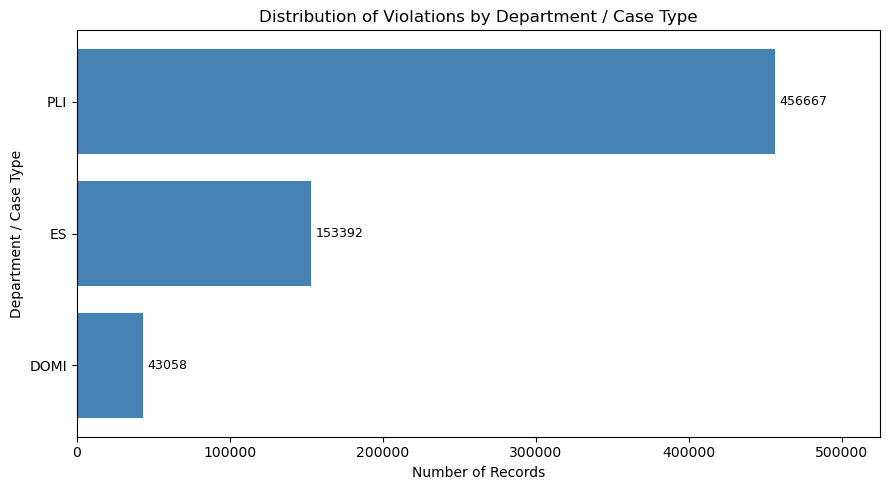

In [19]:
# Extract department type from case file numbers
def extract_department(case_no):
    if pd.isna(case_no):
        return 'Unknown'
    parts = str(case_no).split('-')
    if len(parts) >= 2:
        return parts[1]
    return 'Other'

df_cleaned['dept_type'] = df_cleaned['casefile_number'].apply(extract_department)
print("=== Department / Violation Type Distribution ===")
print(df_cleaned['dept_type'].value_counts())

# Visualize violation types by department
dept_counts = df_cleaned['dept_type'].value_counts()print('=== Sample Case File Numbers ===')
display(df_cleaned['casefile_number'].dropna().astype(str).head(10))

def extract_department(case_no):
    if pd.isna(case_no):
        return 'Unknown'
    parts = str(case_no).split('-')
    return parts[1].strip().upper() if len(parts) >= 2 else 'Other'
df_cleaned['dept_type'] = df_cleaned['casefile_number'].apply(extract_department)
dept_counts = df_cleaned['dept_type'].value_counts()
print('=== Department / Case Type Distribution ===')
display(dept_counts)
plt.figure(figsize=(9, max(5, len(dept_counts) * 0.5)))
bars = plt.barh(dept_counts.index, dept_counts.values, color='steelblue')
plt.bar_label(bars, padding=3, fontsize=9)
plt.title('Distribution of Violations by Department / Case Type')
plt.xlabel('Number of Records')
plt.ylabel('Department / Case Type')
plt.gca().invert_yaxis()
plt.xlim(right=dept_counts.max() * 1.15)
plt.tight_layout()
plt.show()

Count the records for every neighborhood. The full chart shows the actual number of recorded violations, rather than a score.

=== Complete Neighborhood Ranking ===


,neighborhood,violation_count
0,Arlington Heights,58
1,Ridgemont,274
2,Northview Heights,319
3,Glen Hazel,378
4,East Carnegie,425
...,...,...
85,Mount Washington,21528
86,Hazelwood,23294
87,Carrick,24018
88,South Side Slopes,29799


,neighborhood,violation_count
0,Arlington Heights,58
1,Ridgemont,274
2,Northview Heights,319
3,Glen Hazel,378
4,East Carnegie,425
...,...,...
85,Mount Washington,21528
86,Hazelwood,23294
87,Carrick,24018
88,South Side Slopes,29799


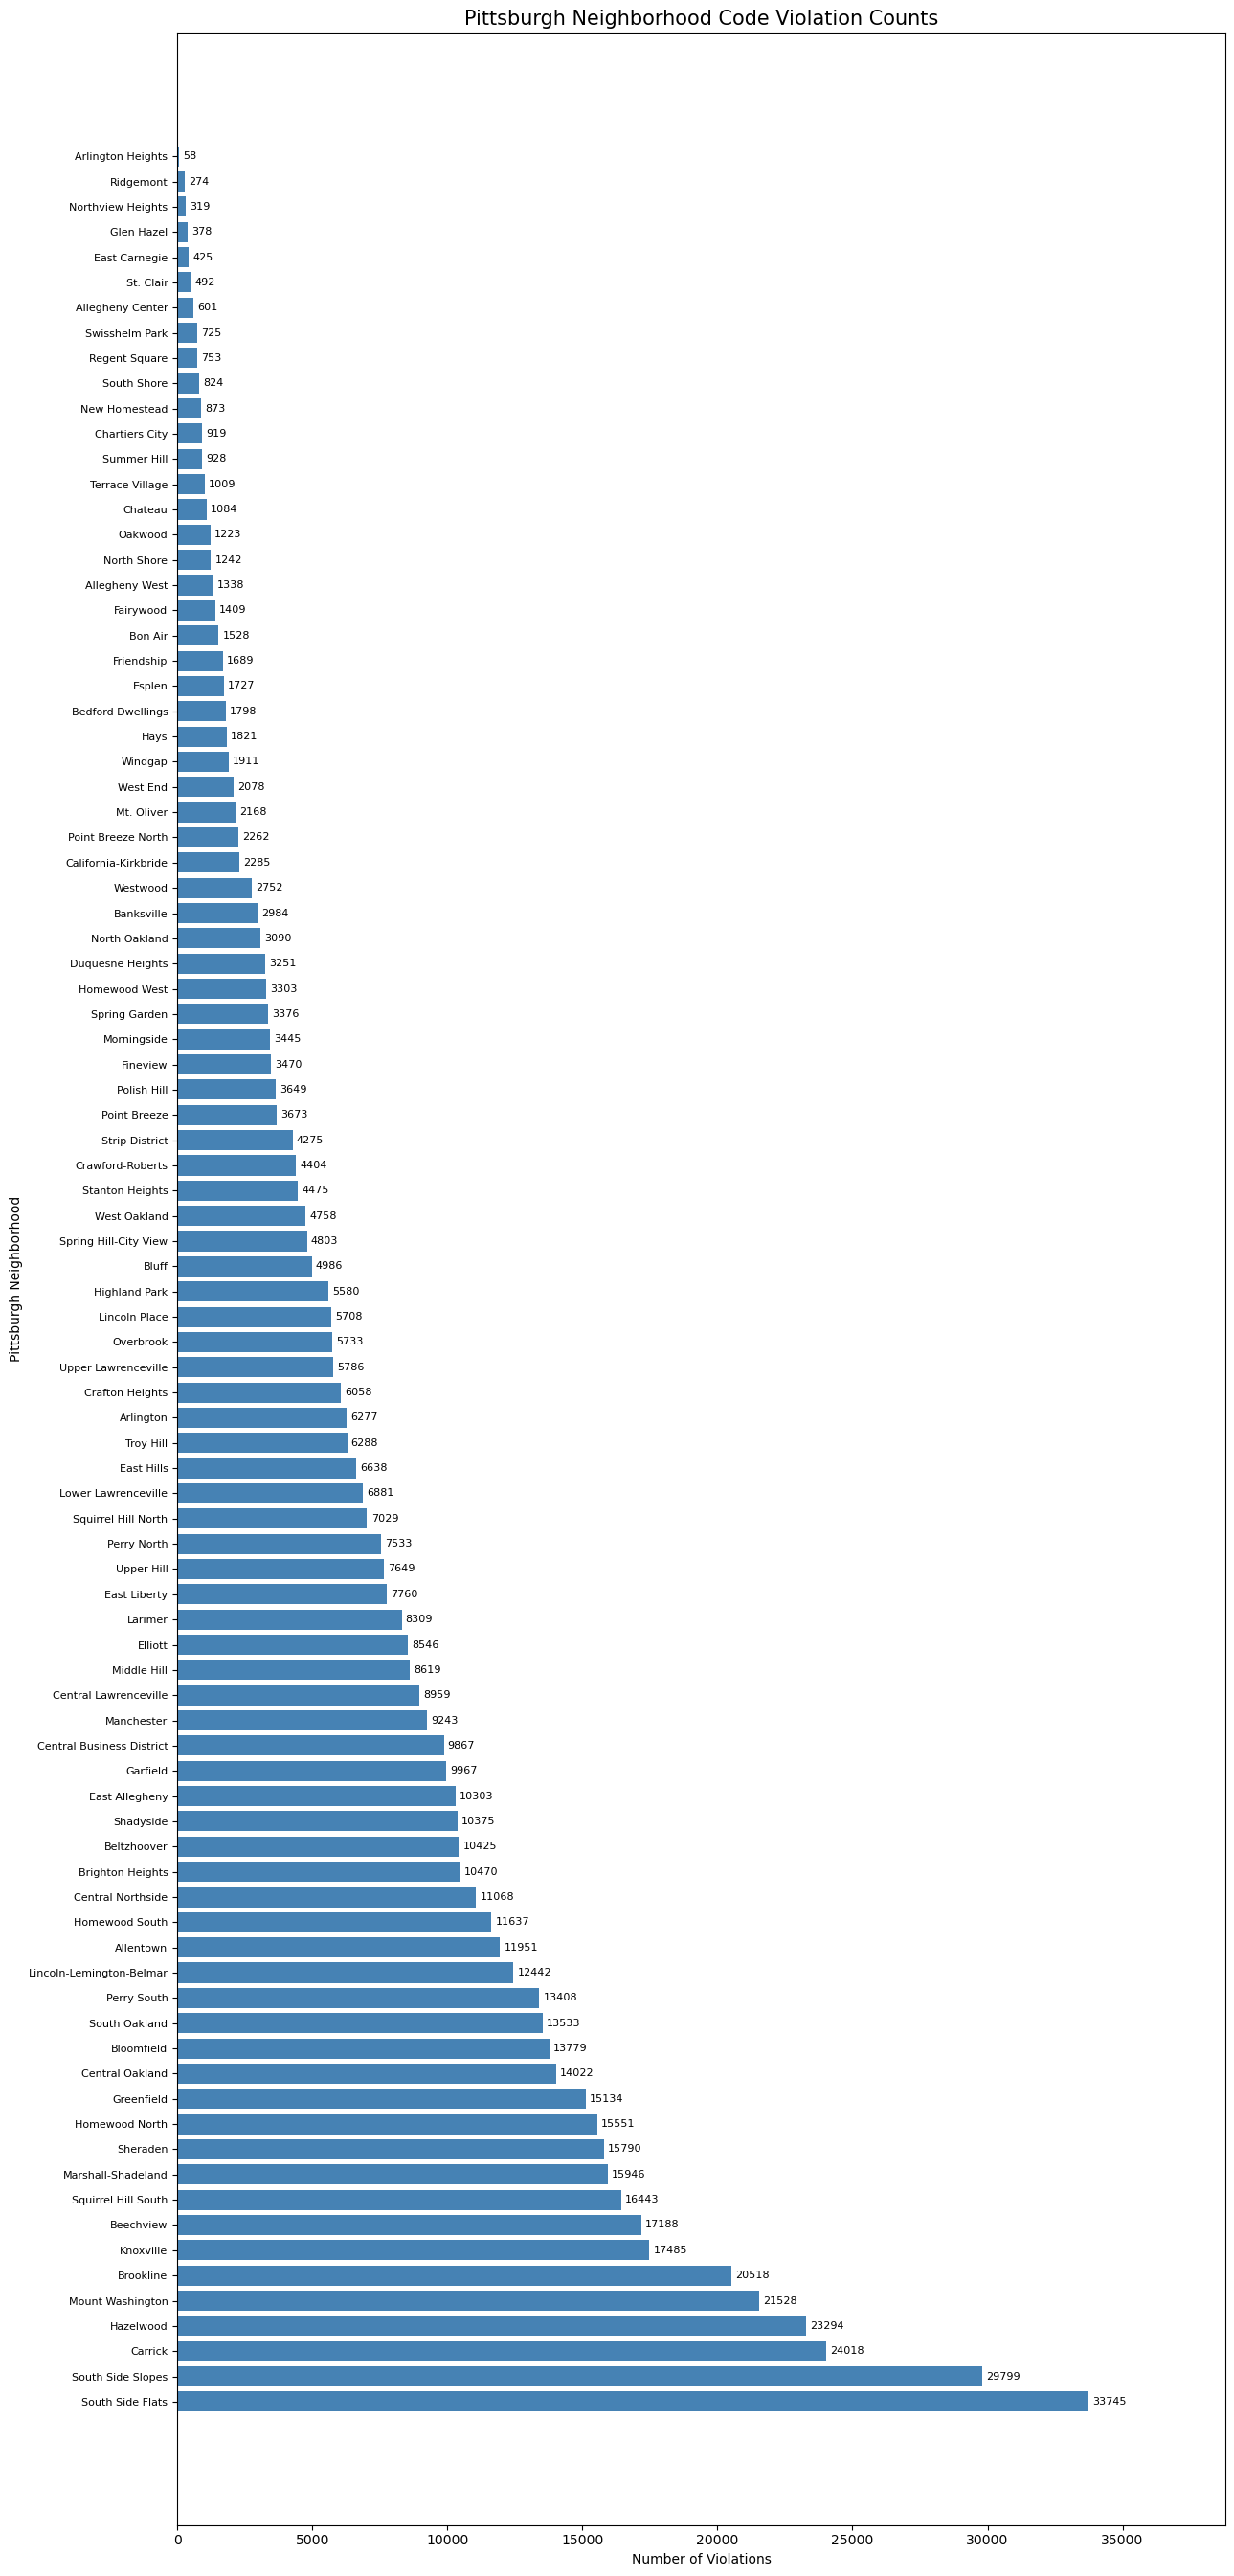

In [20]:
# Count violations in each neighborhood
violation_counts = (df_cleaned['clean_neighborhood'].value_counts().reset_index())
violation_counts.columns = ['neighborhood', 'violation_count']
# Rank neighborhoods by violation count
violation_counts = (violation_counts.sort_values(by='violation_count', ascending=True).reset_index(drop=True))
print("=== Complete Neighborhood Ranking ===")
display(violation_counts)# Count and sort recorded violations
violation_counts = df_cleaned['clean_neighborhood'].value_counts().reset_index()
violation_counts.columns = ['neighborhood', 'violation_count']
violation_counts = violation_counts.sort_values(by=['violation_count', 'neighborhood'], ascending=[True, True]).reset_index(drop=True)
display(violation_counts)
figure_height = max(17, len(violation_counts) * 0.3)
plt.figure(figsize=(13, figure_height))
bars = plt.barh(violation_counts['neighborhood'], violation_counts['violation_count'], color='steelblue')
plt.bar_label(bars, padding=3, fontsize=8)
plt.title('Pittsburgh Neighborhood Code Violation Counts', fontsize=15)
plt.xlabel('Number of Violations')
plt.ylabel('Pittsburgh Neighborhood')
plt.yticks(fontsize=8)
plt.gca().invert_yaxis()
plt.xlim(right=violation_counts['violation_count'].max() * 1.15)
plt.tight_layout()
plt.savefig('violation_counts.png', dpi=300, bbox_inches='tight')
plt.show()

Rank neighborhoods from fewest to most recorded violations. Equal counts receive the same rank; dense ranking keeps the rank sequence consecutive.

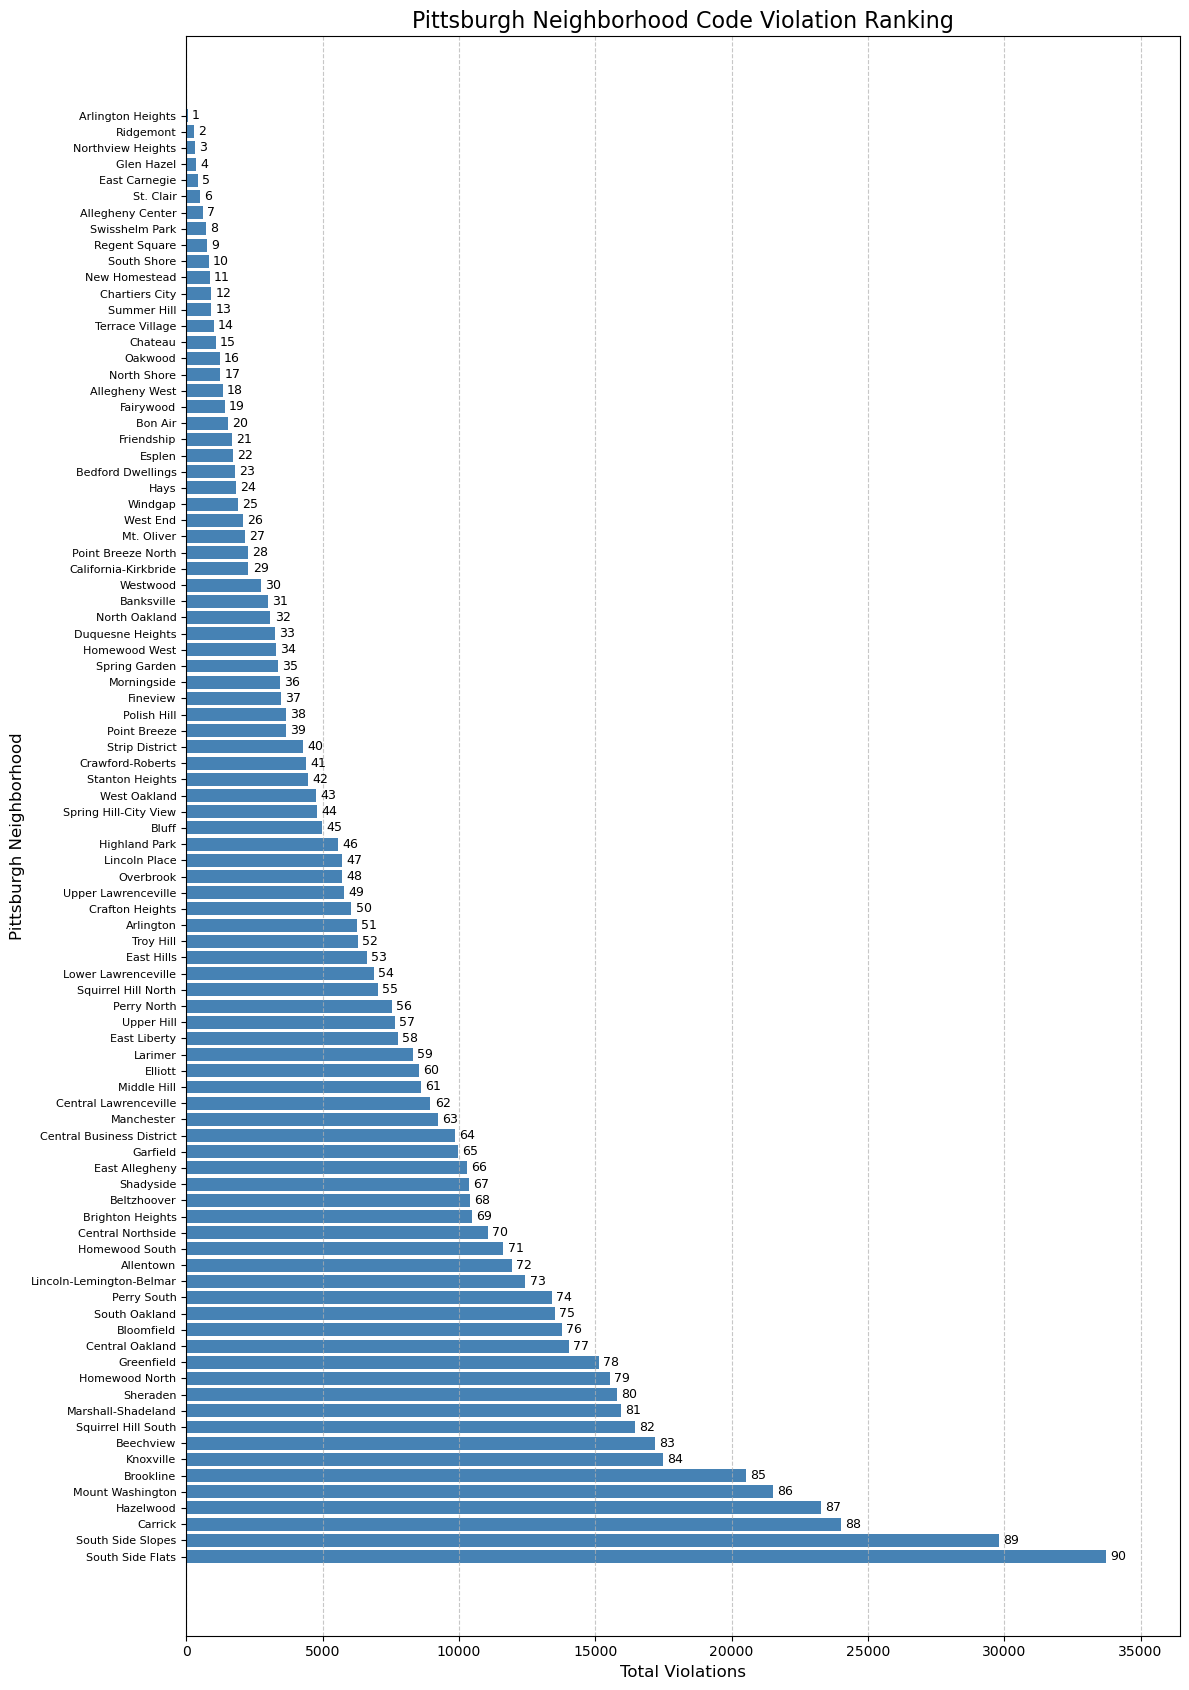

=== Neighborhood Ranking ===


,neighborhood,violation_count,rank
0,Arlington Heights,58,1
1,Ridgemont,274,2
2,Northview Heights,319,3
3,Glen Hazel,378,4
4,East Carnegie,425,5
...,...,...,...
85,Mount Washington,21528,86
86,Hazelwood,23294,87
87,Carrick,24018,88
88,South Side Slopes,29799,89


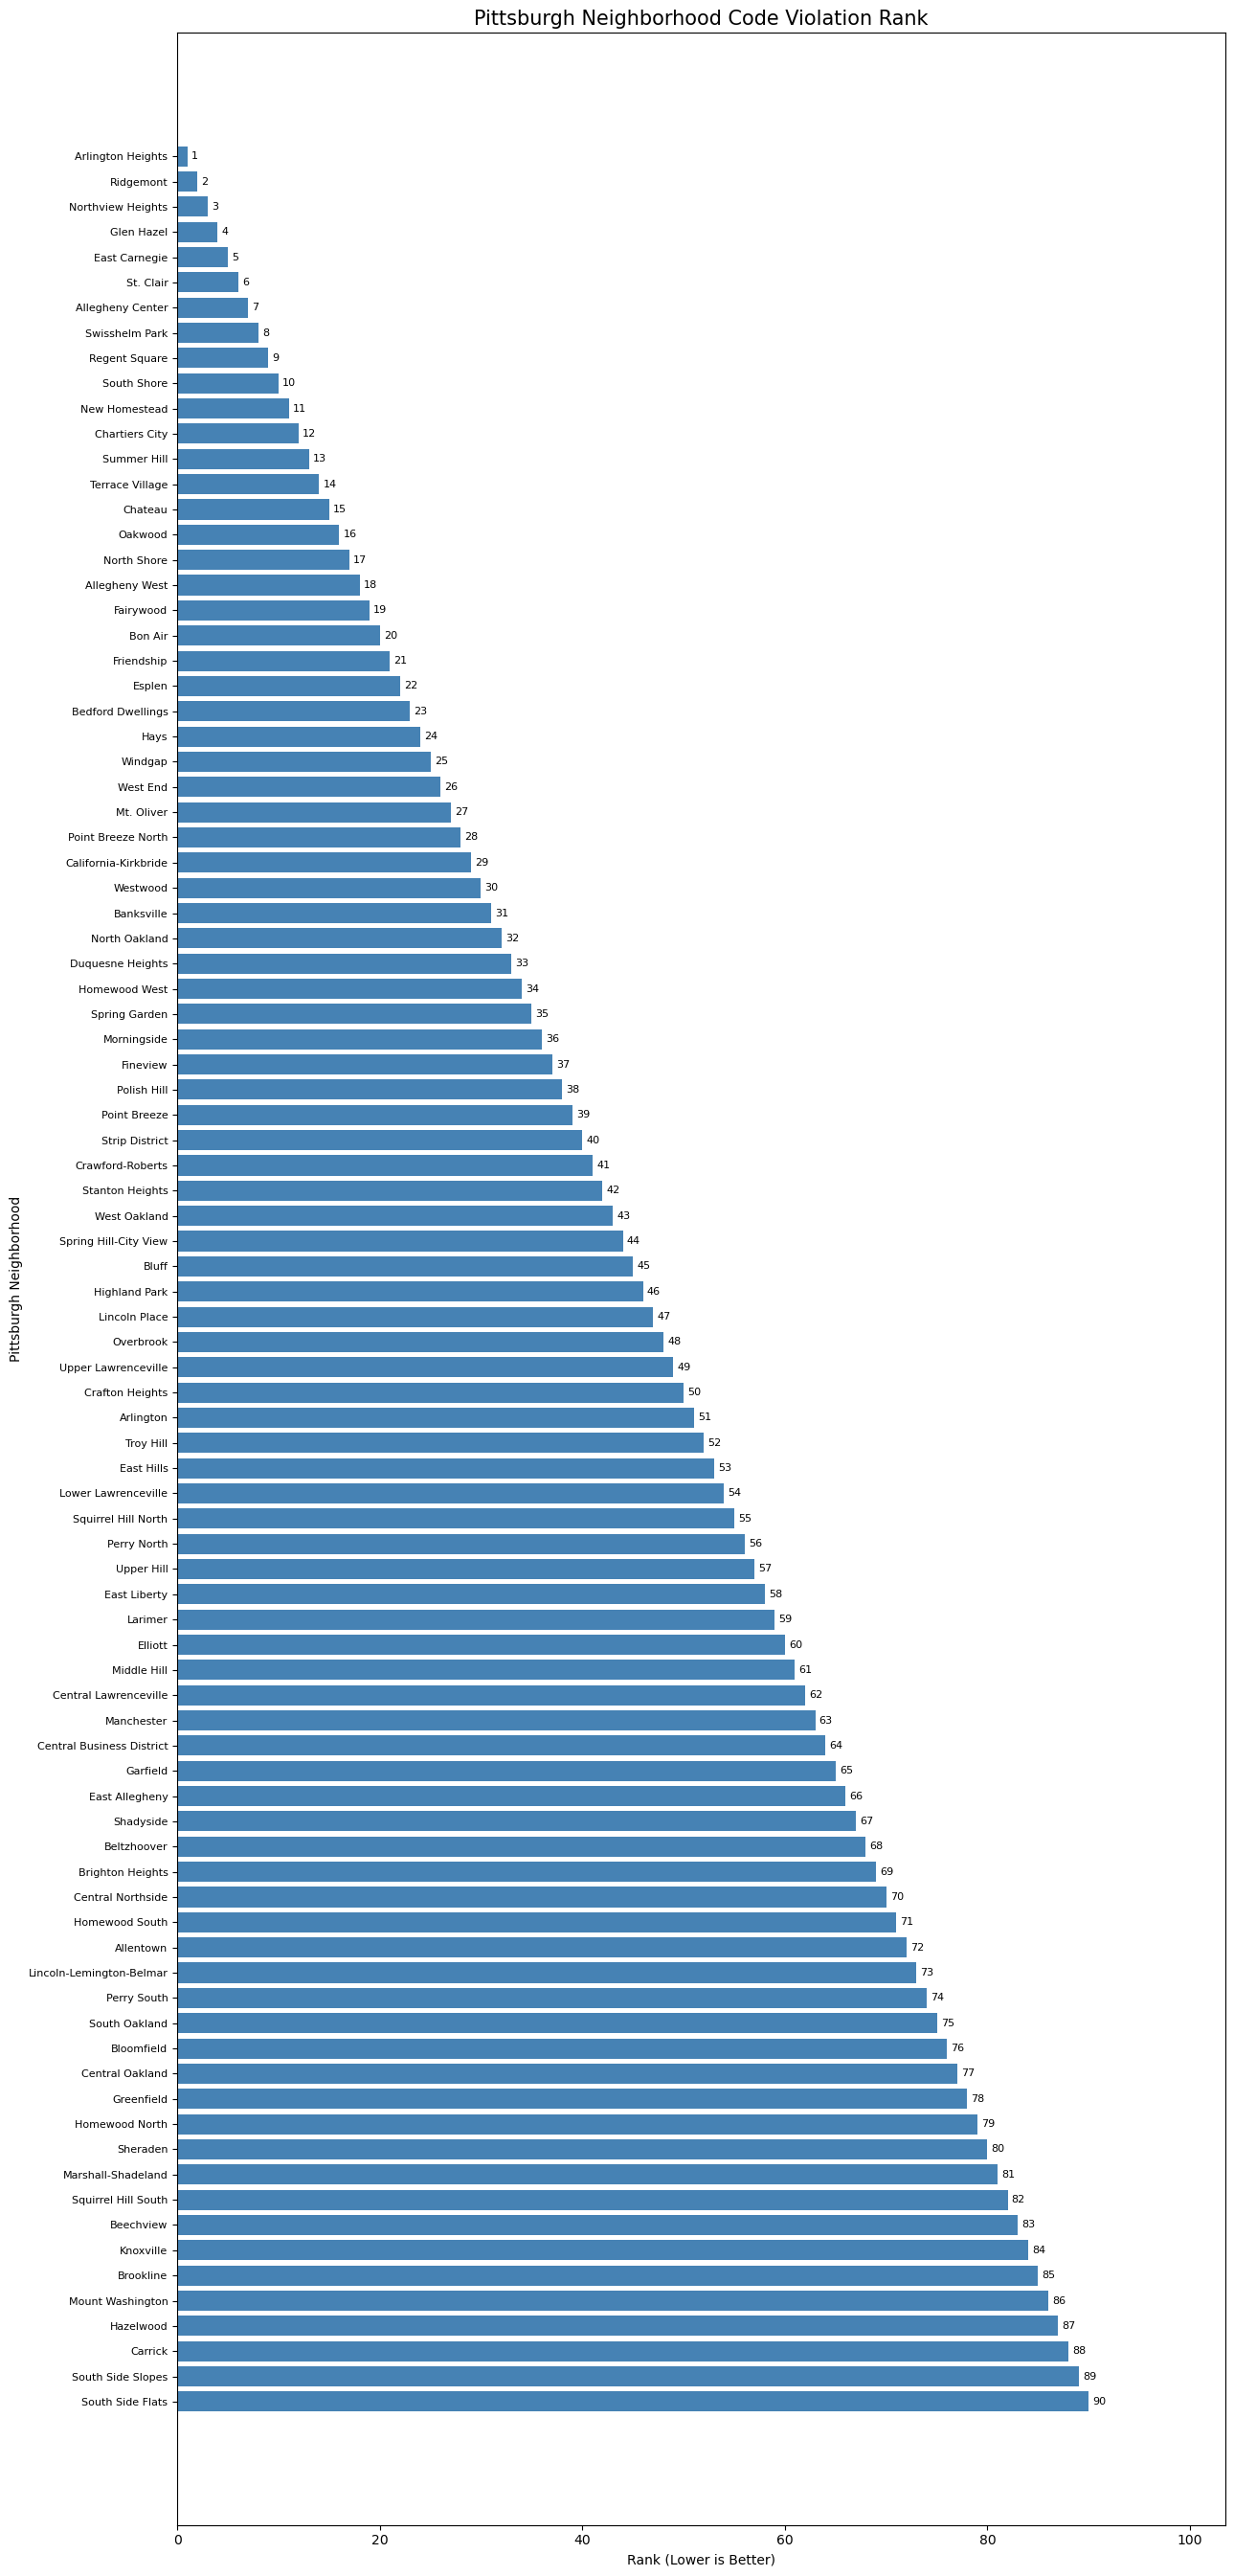

In [21]:
violation_counts = violation_counts.sort_values(by='violation_count', ascending=True).reset_index(drop=True)
violation_counts['rank'] = violation_counts['violation_count'].rank(method='dense', ascending=True).astype(int)
plt.figure(figsize=(12, 17))
bars = plt.barh(violation_counts['neighborhood'], violation_counts['violation_count'], color='steelblue')
plt.bar_label(bars, labels=violation_counts['rank'].astype(str), padding=3, fontsize=9)
plt.title('Pittsburgh Neighborhood Code Violation Ranking', fontsize=16)
plt.xlabel('Total Violations', fontsize=12)
plt.ylabel('Pittsburgh Neighborhood', fontsize=12)
plt.yticks(fontsize=8) 
plt.gca().invert_yaxis()
plt.xlim(right=violation_counts['violation_count'].max() * 1.08)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('complete_neighborhood_ranking.png', dpi=300, bbox_inches='tight')
plt.show()# Equal violation counts receive equal ranks
violation_counts['rank'] = violation_counts['violation_count'].rank(method='dense', ascending=True).astype(int)
rank_order = violation_counts.sort_values(by=['rank', 'neighborhood'], ascending=[True, True])
print('=== Neighborhood Ranking ===')
display(rank_order[['neighborhood', 'violation_count', 'rank']])
plt.figure(figsize=(13, figure_height))
bars = plt.barh(rank_order['neighborhood'], rank_order['rank'], color='steelblue')
plt.bar_label(bars, padding=3, fontsize=8)
plt.title('Pittsburgh Neighborhood Code Violation Rank', fontsize=15)
plt.xlabel('Rank (Lower is Better)')
plt.ylabel('Pittsburgh Neighborhood')
plt.yticks(fontsize=8)
plt.gca().invert_yaxis()
plt.xlim(right=rank_order['rank'].max() * 1.15)
plt.tight_layout()
plt.savefig('violation_rank.png', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
max_v = violation_counts['violation_count'].max()
min_v = violation_counts['violation_count'].min()
if max_v == min_v:
    violation_counts['violation_score'] = 100.0
else:
    violation_counts['violation_score'] = 100 * (1 - (violation_counts['violation_count'] - min_v) / (max_v - min_v))
# Sort neighborhoods by score
violation_counts = (violation_counts.sort_values(by='violation_score', ascending=False).reset_index(drop=True))
print("=== top 5 Neighborhoods After Normalization ===")
display(violation_counts.head(5))
# Export scores for group combination
output_filename = 'submetric_pli_violations_scored.csv'
violation_counts.to_csv(output_filename, index=False)
print(f"Successfully exported scores to '{output_filename}'.")

=== top 5 Neighborhoods After Normalization ===


,neighborhood,violation_count,violation_score
0,Arlington Heights,58,100.000000
1,Ridgemont,274,99.358803
2,Northview Heights,319,99.225220
3,Glen Hazel,378,99.050079
4,East Carnegie,425,98.910559


Successfully exported scores to 'submetric_pli_violations_scored.csv'.


Convert dense ranks to proportions by dividing by the number of distinct ranks. The lowest proportion represents the best result for this metric. This is the only standardized metric used in the final analysis; the earlier 0–100 Min-Max score has been removed.

In [22]:
# Scale dense ranks using the number of unique ranks
violation_counts['rank_proportion'] = violation_counts['rank'] / violation_counts['rank'].nunique()
print('=== Rank Proportion (Alphabetical Order) ===')
display(violation_counts[['neighborhood', 'rank_proportion']].sort_values(by='neighborhood'))
print('=== Rank Proportion (Numerical Order) ===')
display(violation_counts[['neighborhood', 'rank_proportion']].sort_values(by='rank_proportion'))

=== Rank Proportion (Alphabetical Order) ===


,neighborhood,rank_proportion
6,Allegheny Center,0.077778
17,Allegheny West,0.200000
71,Allentown,0.800000
50,Arlington,0.566667
0,Arlington Heights,0.011111
...,...,...
48,Upper Lawrenceville,0.544444
25,West End,0.288889
42,West Oakland,0.477778
29,Westwood,0.333333


=== Rank Proportion (Numerical Order) ===


,neighborhood,rank_proportion
0,Arlington Heights,0.011111
1,Ridgemont,0.022222
2,Northview Heights,0.033333
3,Glen Hazel,0.044444
4,East Carnegie,0.055556
...,...,...
85,Mount Washington,0.955556
86,Hazelwood,0.966667
87,Carrick,0.977778
88,South Side Slopes,0.988889


This view makes it easy to find individual neighborhoods by name.

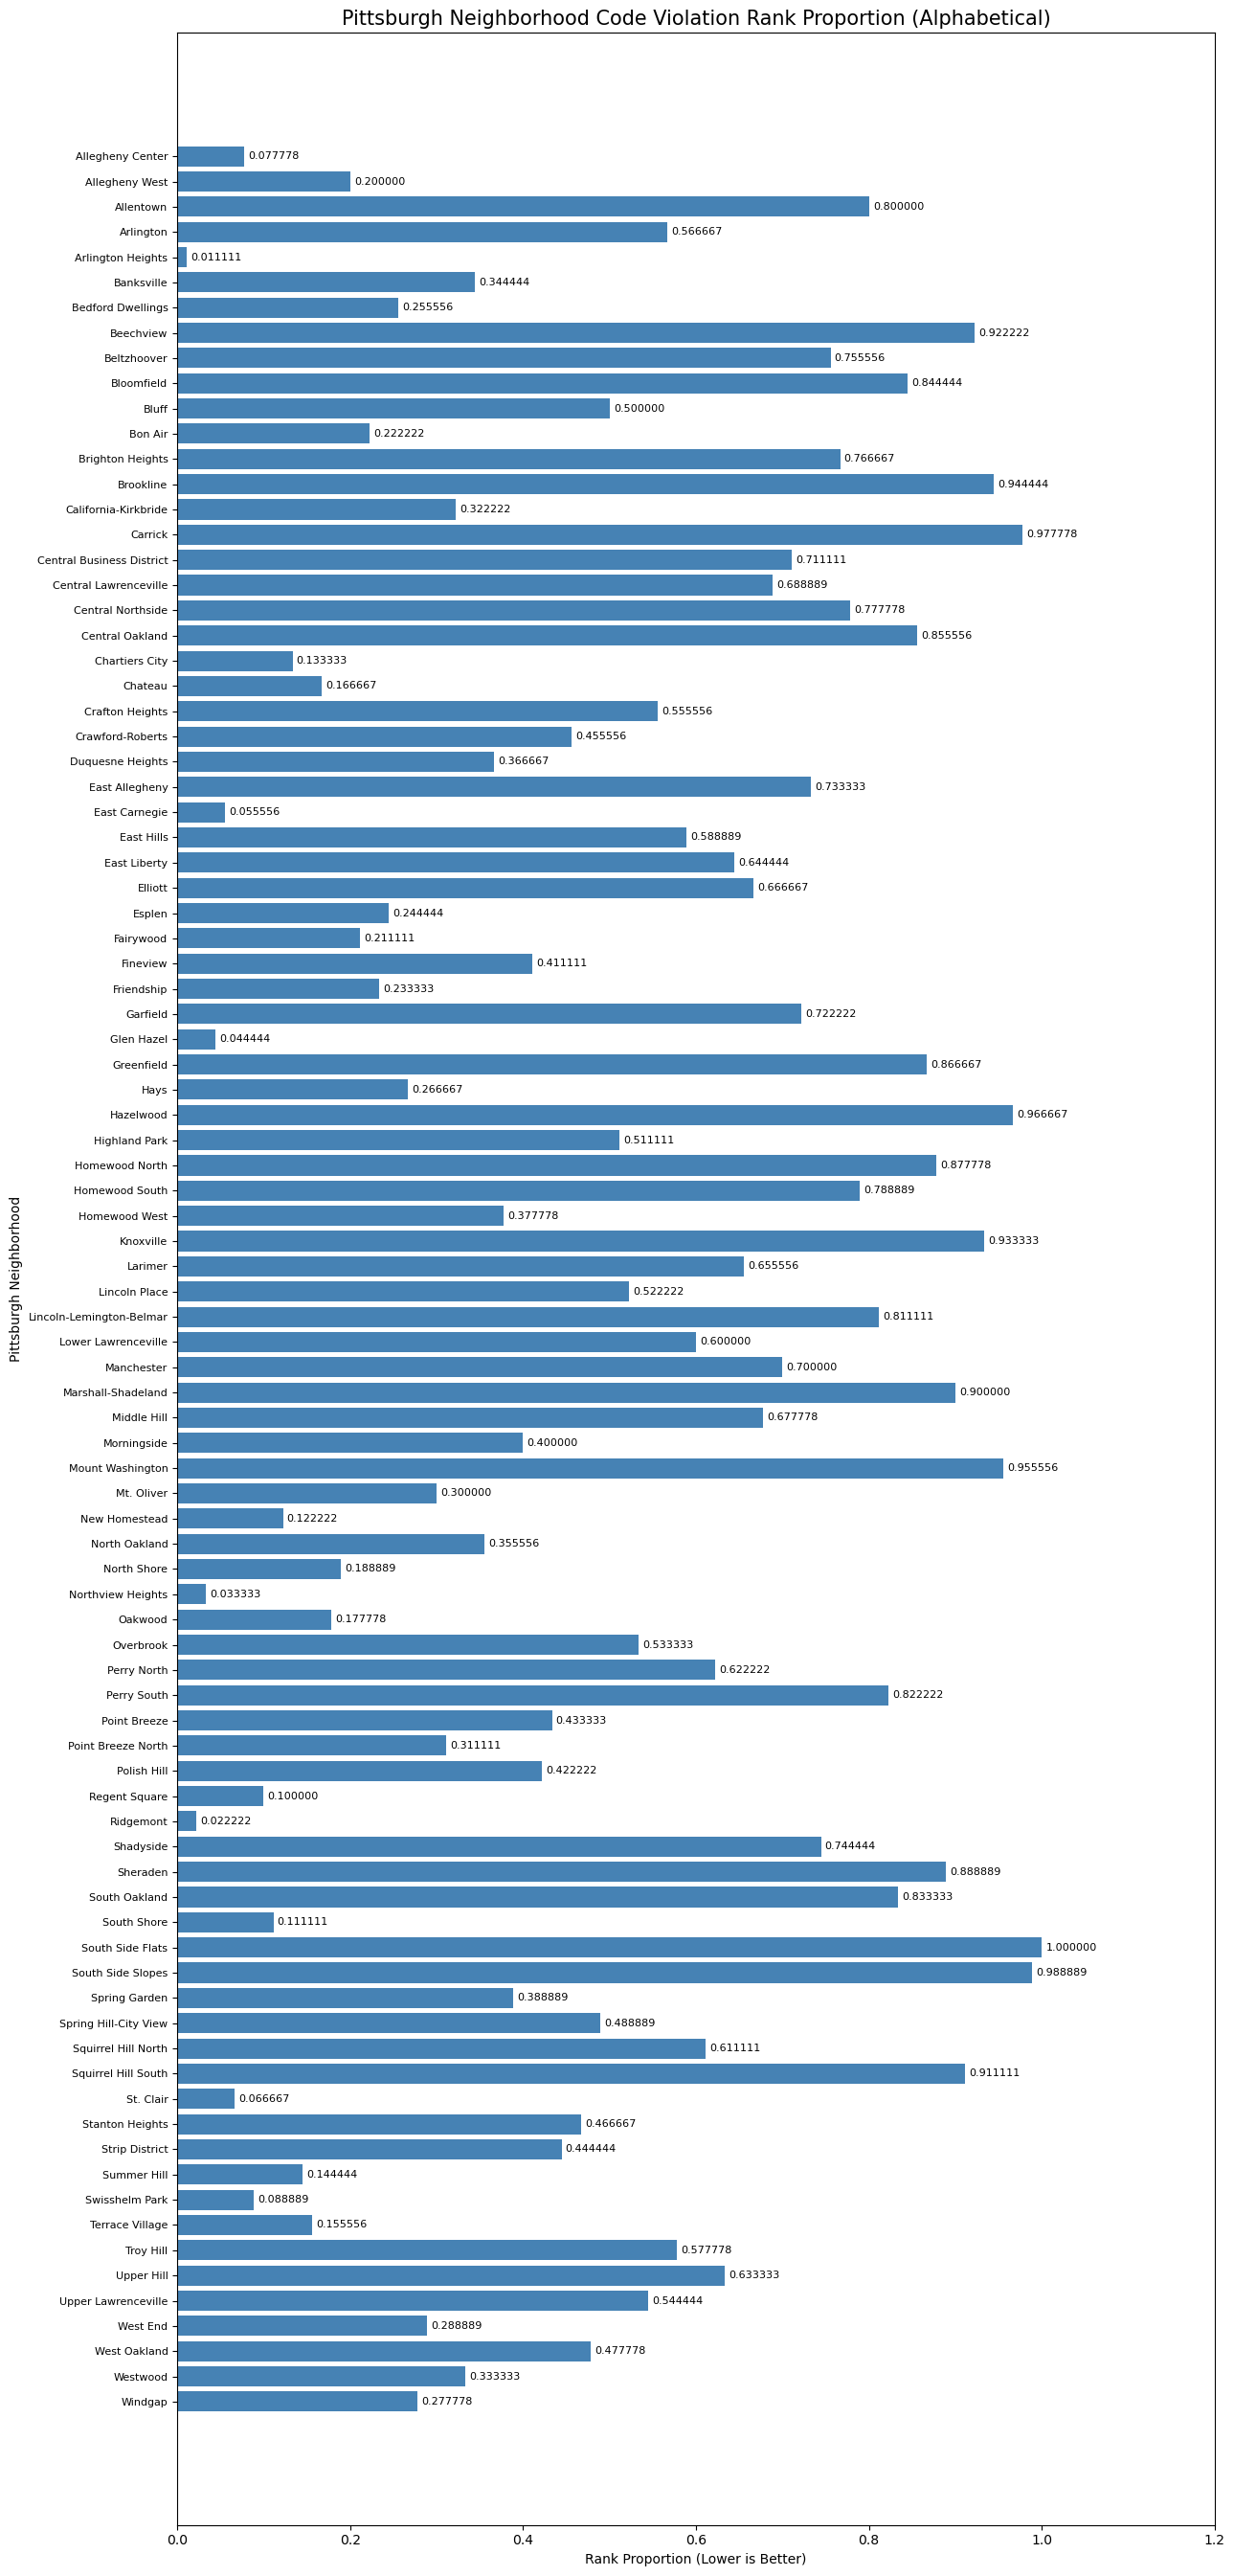

In [23]:
alphabetical = violation_counts.sort_values(by='neighborhood', ascending=False)
plt.figure(figsize=(13, figure_height))
bars = plt.barh(alphabetical['neighborhood'], alphabetical['rank_proportion'], color='steelblue')
plt.bar_label(bars, fmt='%.6f', padding=3, fontsize=8)
plt.title('Pittsburgh Neighborhood Code Violation Rank Proportion (Alphabetical)', fontsize=15)
plt.xlabel('Rank Proportion (Lower is Better)')
plt.ylabel('Pittsburgh Neighborhood')
plt.yticks(fontsize=8)
plt.xlim(right=max(1.05, alphabetical['rank_proportion'].max() * 1.2))
plt.tight_layout()
plt.savefig('violation_rank_proportion_alphabetical.png', dpi=300, bbox_inches='tight')
plt.show()

This view sorts neighborhoods from best to worst according to the violation metric.

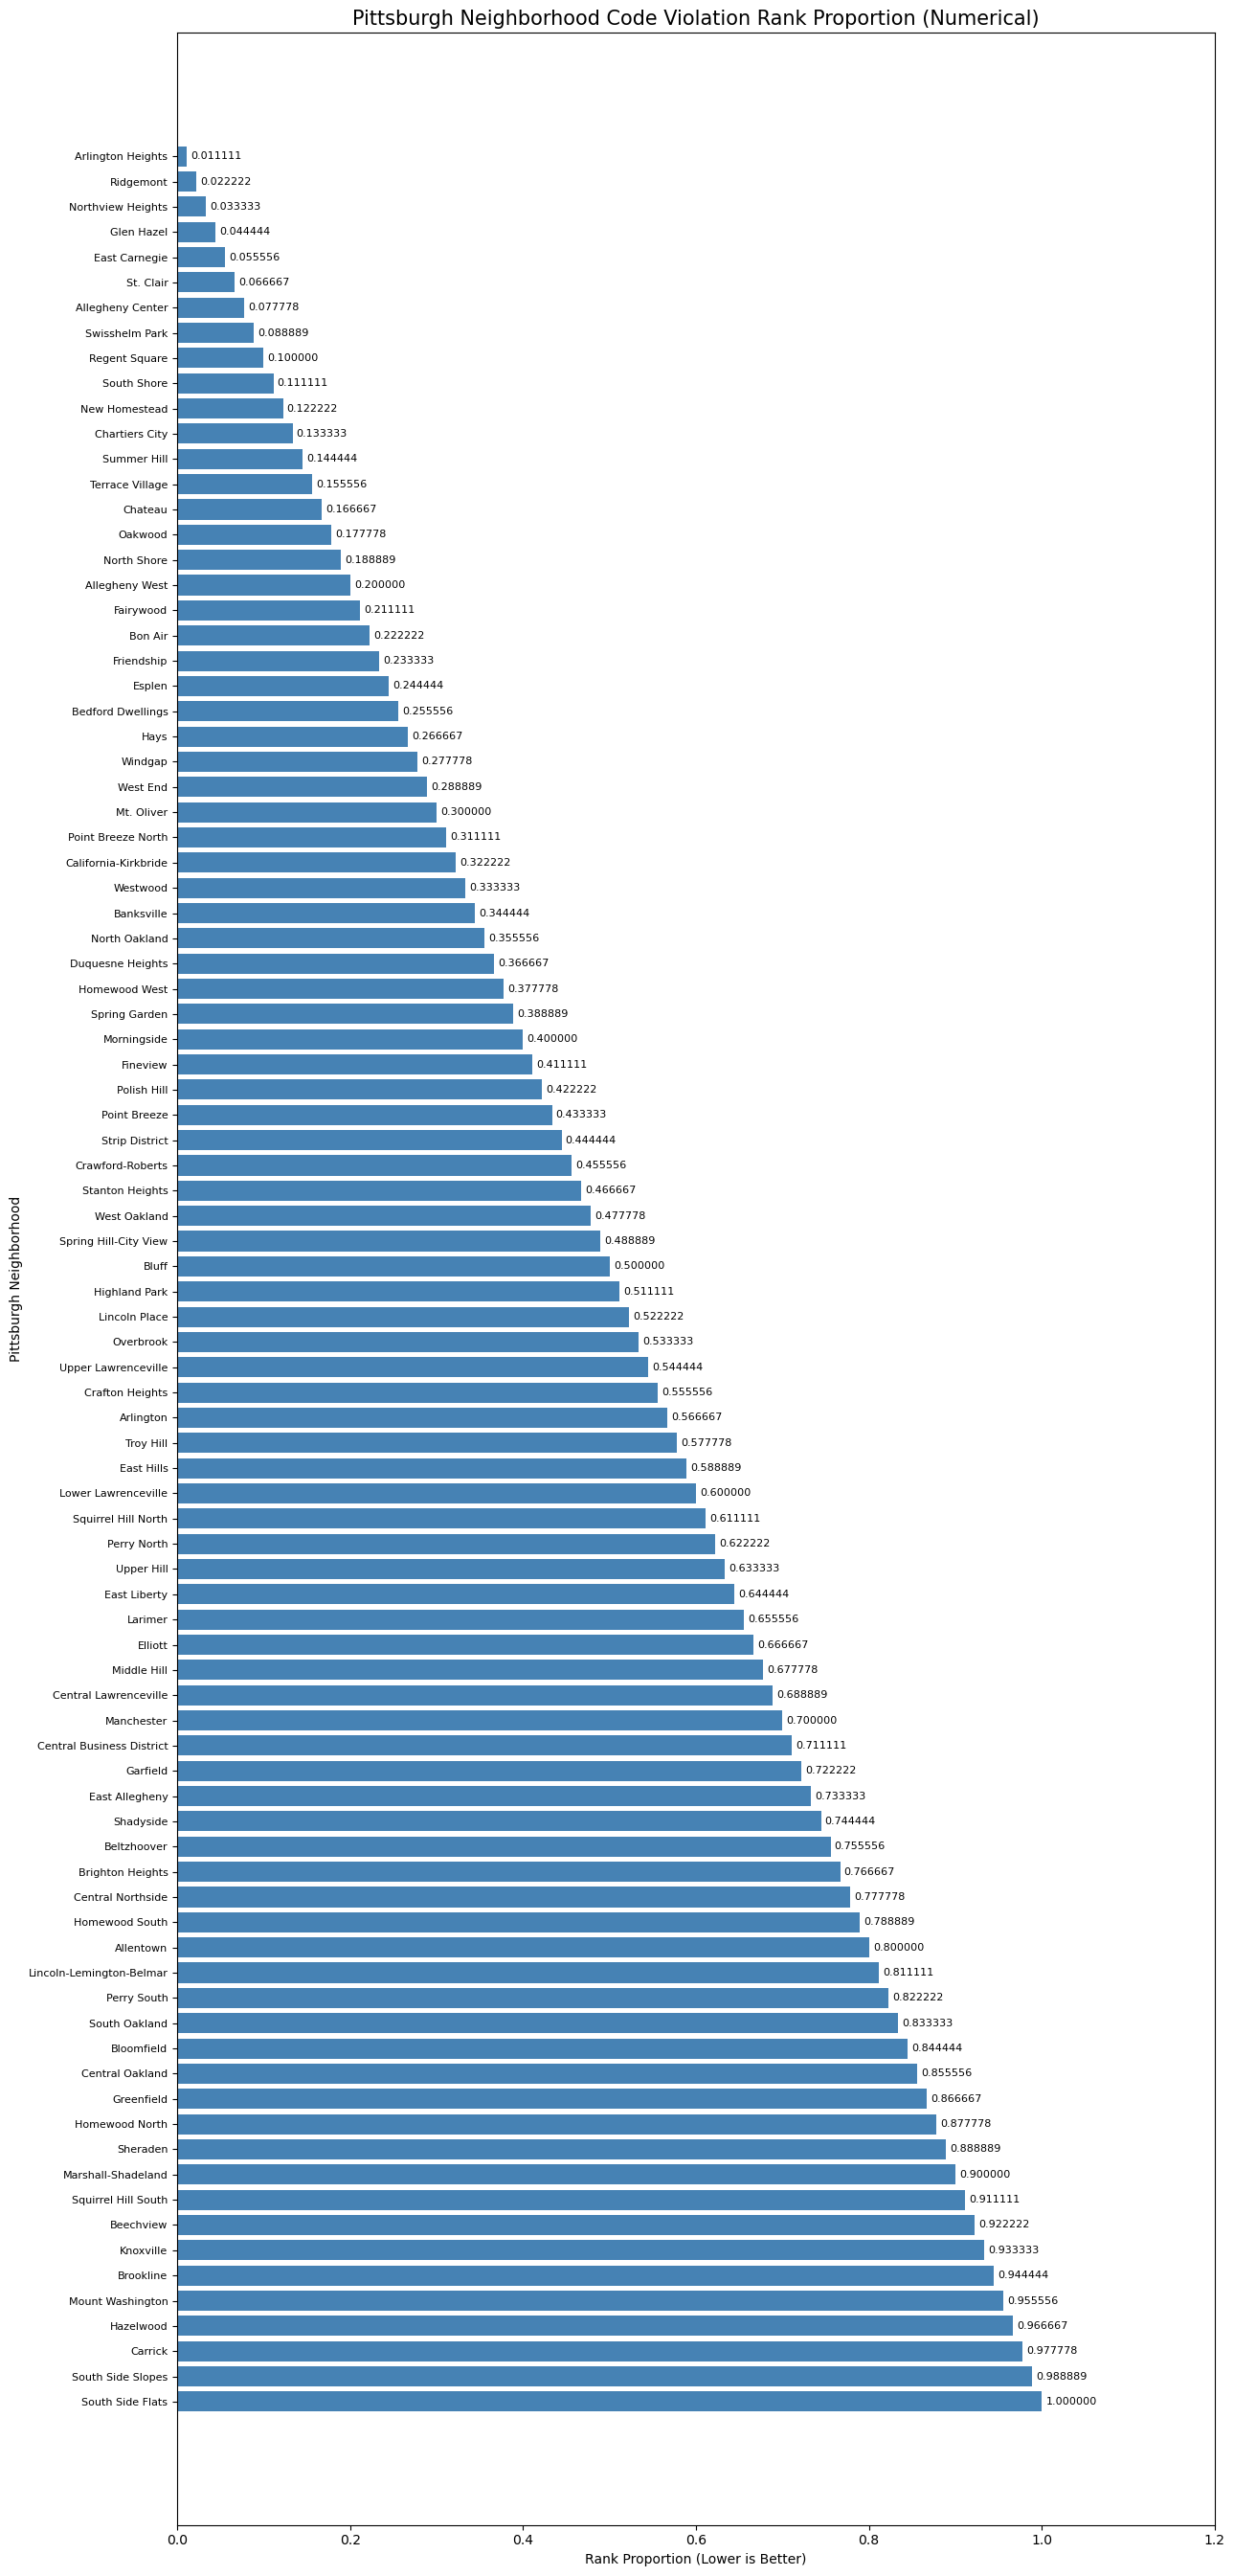

In [24]:
numerical = violation_counts.sort_values(by=['rank_proportion', 'neighborhood'], ascending=[False, False])
plt.figure(figsize=(13, figure_height))
bars = plt.barh(numerical['neighborhood'], numerical['rank_proportion'], color='steelblue')
plt.bar_label(bars, fmt='%.6f', padding=3, fontsize=8)
plt.title('Pittsburgh Neighborhood Code Violation Rank Proportion (Numerical)', fontsize=15)
plt.xlabel('Rank Proportion (Lower is Better)')
plt.ylabel('Pittsburgh Neighborhood')
plt.yticks(fontsize=8)
plt.xlim(right=max(1.05, numerical['rank_proportion'].max() * 1.2))
plt.tight_layout()
plt.savefig('violation_rank_proportion_numerical.png', dpi=300, bbox_inches='tight')
plt.show()

Results

In [25]:
print('=== Best Neighborhoods ===')
display(violation_counts.sort_values(by=['rank_proportion', 'neighborhood'], ascending=[True, True]).head(10))

=== Best Neighborhoods ===


,neighborhood,violation_count,rank,rank_proportion
0,Arlington Heights,58,1,0.011111
1,Ridgemont,274,2,0.022222
2,Northview Heights,319,3,0.033333
3,Glen Hazel,378,4,0.044444
4,East Carnegie,425,5,0.055556
5,St. Clair,492,6,0.066667
6,Allegheny Center,601,7,0.077778
7,Swisshelm Park,725,8,0.088889
8,Regent Square,753,9,0.100000
9,South Shore,824,10,0.111111


The group can join this table with the other submetrics using the neighborhood name. Lower rank proportions are better. The group should agree on how to handle neighborhoods missing from one or more datasets before computing an overall result.

In [26]:
violation_export = violation_counts[['neighborhood', 'violation_count', 'rank', 'rank_proportion']].sort_values(by='neighborhood').reset_index(drop=True)
display(violation_export)
violation_export.to_csv('pittsburgh_violation_rank_proportion.csv', index=False)
print('Successfully exported pittsburgh_violation_rank_proportion.csv')

,neighborhood,violation_count,rank,rank_proportion
0,Allegheny Center,601,7,0.077778
1,Allegheny West,1338,18,0.200000
2,Allentown,11951,72,0.800000
3,Arlington,6277,51,0.566667
4,Arlington Heights,58,1,0.011111
...,...,...,...,...
85,Upper Lawrenceville,5786,49,0.544444
86,West End,2078,26,0.288889
87,West Oakland,4758,43,0.477778
88,Westwood,2752,30,0.333333


Successfully exported pittsburgh_violation_rank_proportion.csv


In [28]:
# Calculate violation rate for each neighborhood
df_rate = df_cleaned[df_cleaned['investigation_outcome'].isin(['Violation Found', 'No Violation Found'])].copy()
violation_rate = df_rate.groupby('clean_neighborhood')['investigation_outcome'].agg(total_records='count',violations=lambda x: (x == 'Violation Found').sum()).reset_index()
violation_rate['violation_rate'] = violation_rate['violations'] / violation_rate['total_records'] * 100
violation_rate = violation_rate.sort_values(by='violation_rate', ascending=True).reset_index(drop=True)
violation_rate['rank'] = violation_rate['violation_rate'].rank(method='dense', ascending=True).astype(int)
display(violation_rate)

,clean_neighborhood,total_records,violations,violation_rate,rank
0,Arlington Heights,20,10,50.000000,1
1,South Side Slopes,14587,8078,55.378076,2
2,South Side Flats,16057,8975,55.894625,3
3,Allegheny Center,249,141,56.626506,4
4,Point Breeze,1617,955,59.059988,5
...,...,...,...,...,...
85,Middle Hill,3136,2763,88.105867,86
86,Fairywood,510,454,89.019608,87
87,Homewood West,1116,994,89.068100,88
88,Beltzhoover,3563,3193,89.615493,89


,clean_neighborhood,total_records,violations,violation_rate,rank
0,Arlington Heights,20,10,50.000000,1
1,South Side Slopes,14587,8078,55.378076,2
2,South Side Flats,16057,8975,55.894625,3
3,Allegheny Center,249,141,56.626506,4
4,Point Breeze,1617,955,59.059988,5
...,...,...,...,...,...
85,Middle Hill,3136,2763,88.105867,86
86,Fairywood,510,454,89.019608,87
87,Homewood West,1116,994,89.068100,88
88,Beltzhoover,3563,3193,89.615493,89


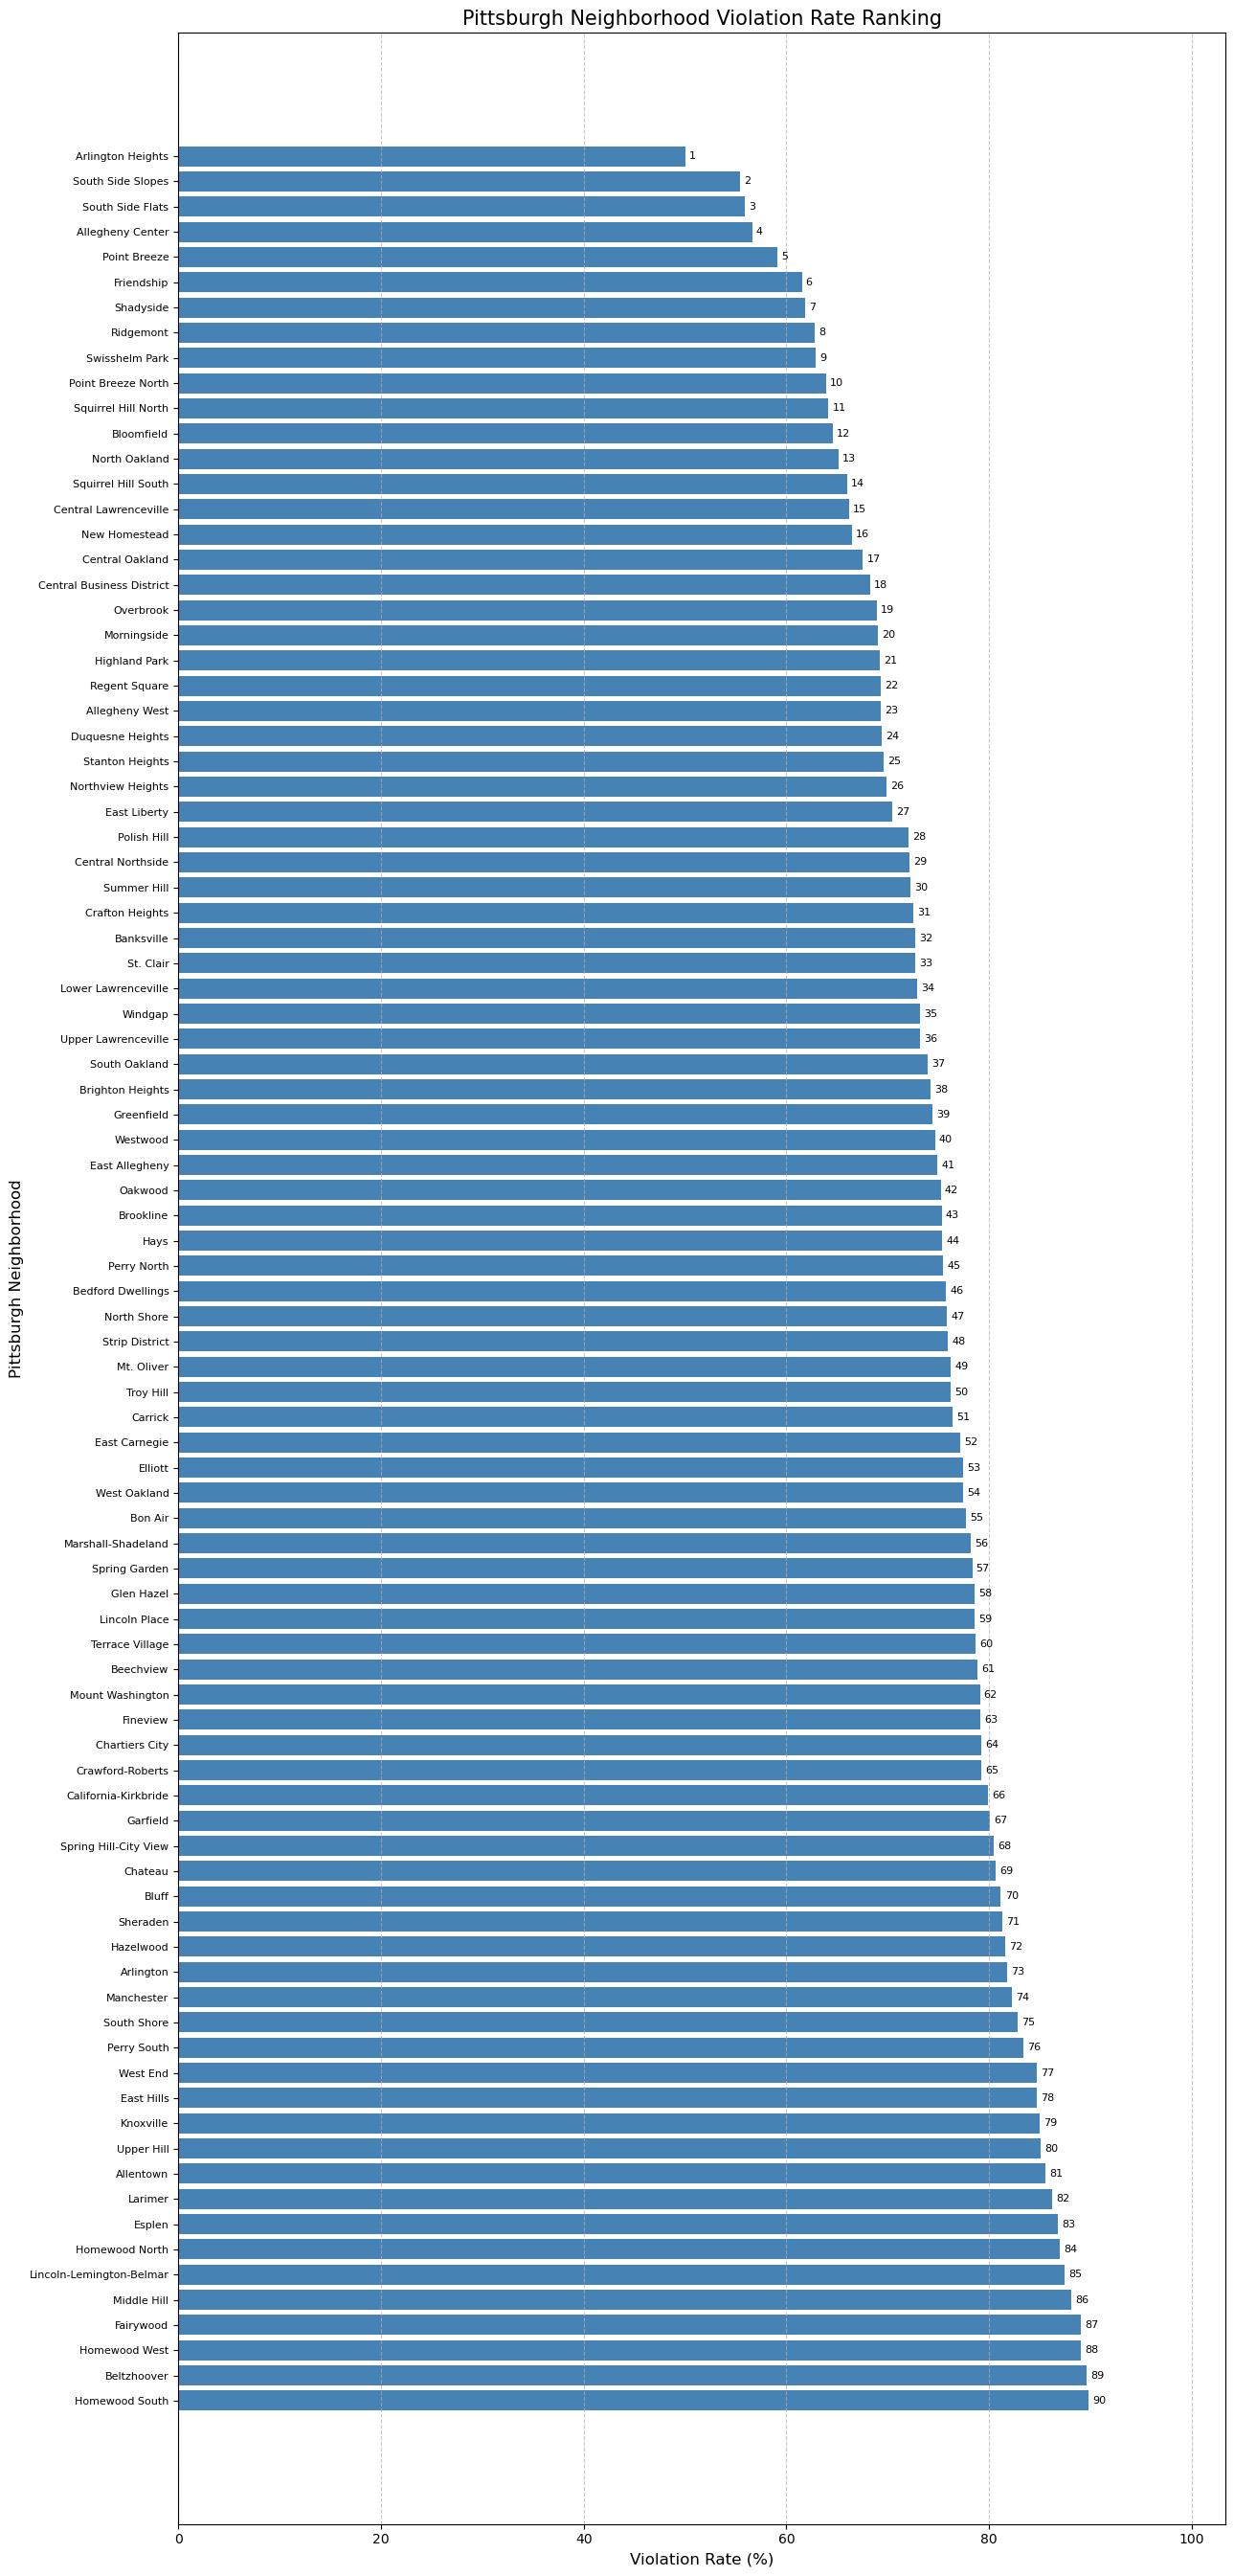

In [30]:
# Rank neighborhoods by violation rate 
violation_rate = violation_rate.sort_values(by=['violation_rate', 'clean_neighborhood'], ascending=[True, True]).reset_index(drop=True)
violation_rate['rank'] = violation_rate['violation_rate'].rank(method='dense', ascending=True).astype(int)
display(violation_rate[['clean_neighborhood', 'total_records', 'violations', 'violation_rate', 'rank']])
figure_height = max(17, len(violation_rate) * 0.3)
plt.figure(figsize=(13, figure_height))
bars = plt.barh(violation_rate['clean_neighborhood'], violation_rate['violation_rate'], color='steelblue')
plt.bar_label(bars, labels=violation_rate['rank'].astype(str), padding=3, fontsize=8)
plt.title('Pittsburgh Neighborhood Violation Rate Ranking', fontsize=15)
plt.xlabel('Violation Rate (%)', fontsize=12)
plt.ylabel('Pittsburgh Neighborhood', fontsize=12)
plt.yticks(fontsize=8)
plt.gca().invert_yaxis()
plt.xlim(right=max(1, violation_rate['violation_rate'].max() * 1.15))
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('violation_rate_ranking.png', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
# Export alphabetically ordered results for group combination
violation_export = violation_counts[['neighborhood', 'violation_count', 'rank']].copy()
violation_export['rank_proportion'] = violation_export['rank'] / violation_export['rank'].nunique()
violation_export = violation_export.sort_values(by='neighborhood').reset_index(drop=True)
display(violation_export)
violation_export.to_csv('pittsburgh_violation_rank_proportion.csv', index=False)
print("Successfully exported pittsburgh_violation_rank_proportion.csv")

,neighborhood,violation_count,rank,rank_proportion
0,Allegheny Center,601,7,0.077778
1,Allegheny West,1338,18,0.200000
2,Allentown,11951,72,0.800000
3,Arlington,6277,51,0.566667
4,Arlington Heights,58,1,0.011111
...,...,...,...,...
85,Upper Lawrenceville,5786,49,0.544444
86,West End,2078,26,0.288889
87,West Oakland,4758,43,0.477778
88,Westwood,2752,30,0.333333


Successfully exported pittsburgh_violation_rank_proportion.csv


Conclusion and Limitations:
My violation-based analysis identifies Arlington Heights as the best-performing Pittsburgh neighborhood for this one submetric. It has the fewest recorded code violations in the analyzed dataset, and its low rank proportion reflects that result. There are important limitations. First, raw violation counts tend to favor smaller neighborhoods because they do not account for population or the number of properties. Second, neighborhoods with more inspections or reports may show more recorded violations even if their actual conditions are similar to those elsewhere. Third, the analysis counts dataset records, which should be checked against the source documentation to determine whether multiple records can refer to one case. Finally, a low number of code violations does not measure transportation, affordability, public spaces, or other features of neighborhood quality. I think this metric is useful as one part of the group's final decision, but it should not decide the overall winner on its own. Combining the violation ranking with the other two submetrics will give a broader picture of what makes a neighborhood desirable.